# Step 2 · Competitive landscape of flying drones (Client: Leonardo S.p.A.)

**Team 28 · Innovation Management (01TXIWS) · A.Y. 2026/27**

This notebook answers the Step 2 questions of the PW, following Tutorial 11 (Section 5), on the same DOCDB family universe as Step 1 and with the Team 28 name harmoniser (`src/harmonize.py`, benchmarked in `03_step2_harmonization_benchmark.ipynb`).

| Question (deck, Step 2) | Section |
|---|---|
| How concentrated is the field, and is it consolidating? | 4 |
| Who are the incumbents, and who are the new entrants? | 5 |
| Which subfields are growing fastest? | 6 |
| Which forces shape the field (PEST)? | `docs/LEONARDO_CLIENT_AND_PEST_ANALYSIS.md` |

## 1. Setup

In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/: go up one level to the repo root, where src/ and config/ are
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists() and (REPO_ROOT.parent / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config_loader import load_config, get_last_complete_year
from src.harmonize import harmonize_applicant_names, six_concentration_measures

cfg = load_config(REPO_ROOT / "config" / "sector.yaml")
print("Repo root:", REPO_ROOT)
print("Sector:", cfg["project"]["sector_name"], "| client:", cfg["project"]["client_name"])

Repo root: /home/jovyan/Patent-study
Sector: Flying drones | client: Leonardo S.p.A.


In [2]:
# ---------------------------------------------------------------- run settings
ENV = "TEST"            # develop on TEST, switch to "PROD" for the final numbers
STEP0_CSV_PATH = None   # None = look for Samuele's uav_final_query_families.csv automatically
USE_CACHE = True        # reuse the PATSTAT extraction saved by a previous run

# ---------------------------------------------------------------- analysis parameters
SECTOR_NAME = cfg["project"]["sector_name"]
CLIENT = "LEONARDO"                                    # harmonised name of the client
YEAR_MIN = int(cfg["time_window"]["year_min"])         # 2004
YEAR_MAX = int(cfg["time_window"]["year_max"])         # 2025
LAST_COMPLETE_YEAR = get_last_complete_year(cfg)       # 2022: the last 3 years are incomplete
IPR_TYPE = cfg["counting_rules"]["ipr_type"]           # "PI": patents of invention only
SPLIT_YEAR = int(cfg["counting_rules"]["incumbent_split_year"])   # 2018: incumbents file before
TOP_N = int(cfg["counting_rules"]["top_n_applicants"]) # 15 rows in the top-applicants table
WINDOW = 3                                             # years per window for concentration over time

# ---------------------------------------------------------------- where the results go
OUT = REPO_ROOT / "outputs" / "step2_competitive_landscape"
OUT.mkdir(parents=True, exist_ok=True)

print(f"{SECTOR_NAME} | ENV={ENV} | families {YEAR_MIN}-{YEAR_MAX}, complete up to {LAST_COMPLETE_YEAR}")
print(f"Incumbents: first family before {SPLIT_YEAR} | top {TOP_N} applicants | {WINDOW}-year windows")

Flying drones | ENV=TEST | families 2004-2025, complete up to 2022
Incumbents: first family before 2018 | top 15 applicants | 3-year windows


## 2. Data: the sector's families, their applicants and their CPC codes

The family universe is the one of Step 0/Step 1: Samuele's `uav_final_query_families.csv` if it is in `data/uav_core_boundary_validation/`, otherwise the fallback query built from `config/sector.yaml` (core CPC/IPC codes + boundary subgroups gated by UAV keywords).

In [3]:
from epo.tipdata.patstat import PatstatClient
from src.step0_loader import find_locked_step0_csv, get_step0_families, iter_batches

patstat = PatstatClient(env=ENV)
db = patstat.orm()

# which family universe are we using? (decides also the name of the saved extraction)
step0_csv = find_locked_step0_csv(cfg, override_path=STEP0_CSV_PATH)
UNIVERSE = "step0csv" if step0_csv is not None else "fallback"
CACHE = REPO_ROOT / "data" / "processed" / f"step2_extract_{ENV}_{UNIVERSE}.pkl"
CACHE.parent.mkdir(parents=True, exist_ok=True)

# the DOCDB families of the sector
step0_df, source = get_step0_families(patstat, db, cfg, override_csv_path=STEP0_CSV_PATH)
fids = step0_df["docdb_family_id"].dropna().astype(int).tolist()

print(f"{len(fids):,} UAV families from {source}")
if "query_source" in step0_df.columns:
    print(step0_df["query_source"].value_counts().to_string())

1,624 UAV families from live_yaml_query
query_source
core_classification    1348
boundary_rescue         276


For every family we query, in batches of 5,000 families:

- **year** = the earliest filing (priority) year among its applications, as in Step 1;
- **applicants** = persons with `applt_seq_nr > 0` (owners, not inventors), with PATSTAT standardised name (`psn_name`), sector and country;
- **CPC codes**, for the subfields of Section 6.

In [4]:
from epo.tipdata.patstat.database.models import TLS201_APPLN, TLS206_PERSON, TLS207_PERS_APPLN, TLS224_APPLN_CPC
from sqlalchemy import func


def fetch_family_data(family_ids):
    "Year, applicants and CPC codes of the given DOCDB families (queried in batches of 5,000)."
    years, applicants, cpcs = [], [], []
    for batch in iter_batches(family_ids, batch_size=5000):
        # 1. family year = earliest filing year among its applications
        years.append(patstat.df(
            db.query(TLS201_APPLN.docdb_family_id.label("unit_id"),
                     func.min(TLS201_APPLN.earliest_filing_year).label("year"))
            .filter(TLS201_APPLN.docdb_family_id.in_(batch), TLS201_APPLN.ipr_type == IPR_TYPE)
            .group_by(TLS201_APPLN.docdb_family_id)
        ))
        # 2. applicants of every family (one row per family and person)
        applicants.append(patstat.df(
            db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), TLS206_PERSON.psn_id,
                     TLS206_PERSON.psn_name, TLS206_PERSON.psn_sector,
                     func.trim(TLS206_PERSON.person_ctry_code).label("ctry"))
            .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
            .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
            .filter(TLS201_APPLN.docdb_family_id.in_(batch), TLS201_APPLN.ipr_type == IPR_TYPE,
                    TLS207_PERS_APPLN.applt_seq_nr > 0)
            .distinct()
        ))
        # 3. CPC codes of every family (blanks removed: "B64U 10/13" -> "B64U10/13")
        cpcs.append(patstat.df(
            db.query(TLS201_APPLN.docdb_family_id.label("unit_id"),
                     func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
            .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
            .filter(TLS201_APPLN.docdb_family_id.in_(batch), TLS201_APPLN.ipr_type == IPR_TYPE)
            .distinct()
        ))
    return {
        "family_year": pd.concat(years, ignore_index=True),
        "raw": pd.concat(applicants, ignore_index=True),
        "family_cpc": pd.concat(cpcs, ignore_index=True),
    }


# quick test on the first 50 families
test = fetch_family_data(fids[:50])
for key, df in test.items():
    print(f"{key}: {len(df):,} rows")
test["raw"].head()

family_year: 50 rows
raw: 100 rows
family_cpc: 520 rows


,unit_id,psn_id,psn_name,psn_sector,ctry
0,36072899,26744619,RAYTHEON COMPANY,COMPANY,US
1,39596616,32464777,THE UNITED STATES OF AMERICA AS REPRESENTED BY...,GOV NON-PROFIT,US
2,38920976,32464777,THE UNITED STATES OF AMERICA AS REPRESENTED BY...,GOV NON-PROFIT,US
3,34837753,19827715,LOCUST USA,COMPANY,US
4,32040150,27550948,ROLLS-ROYCE,COMPANY,GB


We also query the **first patent ever** (in any field) of each applicant, to tell newcomers to patenting from established patentees that enter drones. The whole extraction is saved in `data/processed/` and reused on the next runs (`USE_CACHE = True`).

In [5]:
def fetch_first_patents(psn_ids):
    "First filing year of each PATSTAT standardised applicant, in any technology."
    parts = []
    for batch in iter_batches(psn_ids, batch_size=5000):
        parts.append(patstat.df(
            db.query(TLS206_PERSON.psn_id,
                     func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
            .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
            .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
            .filter(TLS206_PERSON.psn_id.in_(batch), TLS207_PERS_APPLN.applt_seq_nr > 0,
                    TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))   # drops the 9999 placeholders
            .group_by(TLS206_PERSON.psn_id)
        ))
    return pd.concat(parts, ignore_index=True)


if USE_CACHE and CACHE.exists():
    data = pd.read_pickle(CACHE)
    print(f"Loaded the saved extraction {CACHE.name}. Set USE_CACHE = False to query PATSTAT again.")
else:
    data = fetch_family_data(fids)
    psn_ids = [int(i) for i in data["raw"]["psn_id"].dropna().unique()]
    data["first_patents"] = fetch_first_patents(psn_ids)
    data["source"] = source
    pd.to_pickle(data, CACHE)
    print(f"Saved the extraction to {CACHE}")

for key in ("family_year", "raw", "family_cpc", "first_patents"):
    print(f"{key:>14}: {len(data[key]):,} rows")

Saved the extraction to /home/jovyan/Patent-study/data/processed/step2_extract_TEST_fallback.pkl
   family_year: 1,624 rows
           raw: 2,265 rows
    family_cpc: 17,820 rows
 first_patents: 1,458 rows


## 3. Applicants: harmonised names, type and country

- **Names**: `src/harmonize.py` with the corporate trees of `config/sector.yaml` (e.g. Finmeccanica, Selex, OTO Melara, AgustaWestland → LEONARDO; Google, X, Wing, Makani → ALPHABET). The Chinese name of X Development loses its characters in the ASCII normalisation, so it is mapped by hand.
- **Individuals are never merged**: they are people, and merging them by surname creates fake applicants (*LEE*, *WANG*). They keep their PATSTAT name.
- Only families with a year between `YEAR_MIN` and `YEAR_MAX` are kept.

In [6]:
# families inside the time window, and their applicants
family_year = data["family_year"].dropna()
family_year = family_year[family_year["year"].between(YEAR_MIN, YEAR_MAX)]
raw = data["raw"].dropna(subset=["psn_name"]).merge(family_year, on="unit_id")

# 1. harmonised names, with the corporate trees of config/sector.yaml
hmap = harmonize_applicant_names(raw["psn_name"].unique(),
                                 domain_groups=cfg["domain_corporate_groups"],
                                 apply_domain_aliases=True)
hmap.update({n: "ALPHABET" for n in hmap if "X开发" in str(n)})   # Chinese name of X Development
raw["applicant"] = raw["psn_name"].map(hmap)

# 2. individuals keep their own PATSTAT name
is_person = raw["psn_sector"].astype(str).str.upper().str.contains("INDIVIDUAL")
raw.loc[is_person, "applicant"] = raw.loc[is_person, "psn_name"]

print(f"{raw['unit_id'].nunique():,} families in {YEAR_MIN}-{YEAR_MAX}")
print(f"{raw['psn_name'].nunique():,} PATSTAT names -> {raw['applicant'].nunique():,} harmonised applicants")
print(f"{is_person.sum():,} rows are individuals (kept with their own name)")

1,608 families in 2004-2025
1,447 PATSTAT names -> 1,288 harmonised applicants
470 rows are individuals (kept with their own name)


For each harmonised applicant: its **type** (firm, university, …, from `psn_sector`), its **country** (the most frequent known one, as in Tutorial 11) and its **first patent ever** (the earliest among the PATSTAT names it groups). Two versions of the family–applicant links are kept: **harmonised** names and **raw** PATSTAT names, to show how much harmonisation changes the measures.

In [7]:
def applicant_type(psn_sector):
    "Translate the PATSTAT psn_sector into the types used in the deck (Tutorial 11)."
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "HOSPITAL" in s:
        return "hospital"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"


# 1. type and main country of each harmonised applicant
raw["type"] = raw["psn_sector"].map(applicant_type)
raw["ctry"] = raw["ctry"].replace("", np.nan)
main_type = raw.groupby("applicant")["type"].agg(lambda t: t.value_counts().index[0])
main_country = (raw.dropna(subset=["ctry"]).drop_duplicates(["unit_id", "applicant", "ctry"])
                .groupby("applicant")["ctry"].agg(lambda c: c.value_counts().index[0]))

# 2. one row per (family, applicant): harmonised names and raw PATSTAT names
links = raw[["unit_id", "year", "applicant"]].drop_duplicates()
links_raw = raw[["unit_id", "year", "psn_name"]].drop_duplicates().rename(columns={"psn_name": "applicant"})

# 3. first patent ever of each harmonised applicant = the earliest among its PATSTAT names
first_ever = (raw[["psn_id", "applicant"]].drop_duplicates()
              .merge(data["first_patents"], on="psn_id")
              .groupby("applicant")["first_patent_year"].min())

print(f"links: {len(links):,} family-applicant pairs (harmonised) | links_raw: {len(links_raw):,} (raw)")
print(main_type.value_counts().to_string())

links: 2,026 family-applicant pairs (harmonised) | links_raw: 2,183 (raw)
type
firm                       573
individual                 421
unknown                    135
university                 128
government / non-profit     31


## 4. Question: how concentrated is the field, and is it consolidating?

First the six measures of Liston-Heyes & Pilkington (2004) on the whole period (complete years only), with **families** in place of patents, **before and after** name harmonisation. Then, in 4b, HH, its numbers-equivalent 1/HH and CR4 on windows of `WINDOW` years: the field is **consolidating** if HH and CR4 rise and 1/HH falls over time.

In [8]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
complete_raw = links_raw[links_raw["year"] <= LAST_COMPLETE_YEAR]

families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()
families_per_name = complete_raw.groupby("applicant")["unit_id"].nunique()

conc = pd.DataFrame({
    "PATSTAT names (raw)": six_concentration_measures(families_per_name.to_numpy()),
    "Harmonised (Team 28)": six_concentration_measures(families_per_applicant.to_numpy()),
})
conc.to_csv(OUT / "concentration_raw_vs_harmonized.csv")
print(f"{SECTOR_NAME}, families {YEAR_MIN}-{LAST_COMPLETE_YEAR}")
conc.round(4)

Flying drones, families 2004-2022


,PATSTAT names (raw),Harmonised (Team 28)
n_applicants,1432.0000,1274.0000
CR4_pct,7.3903,9.7112
CR8_pct,12.0554,14.1434
HH,0.0029,0.0041
numbers_equivalent_1_over_HH,341.9585,242.6907
CV,1.7860,2.0622
Gini,0.3169,0.3424
Lotka_L,-1.6129,-1.5458
Lotka_p_value,0.0000,0.0000


### 4.1 Concentration over time

Windows of `WINDOW` consecutive years, aligned on the last complete year (e.g. 2020-2022, 2017-2019, …), for harmonised and raw names.

In [9]:
def windows(last, first, size):
    "Consecutive windows of `size` years ending on `last`, all starting on or after `first`."
    ends = range(last, first + size - 2, -size)
    return sorted((end - size + 1, end) for end in ends)


KEEP = ["n_applicants", "CR4_pct", "CR8_pct", "HH", "numbers_equivalent_1_over_HH"]
rows = []
for start, end in windows(LAST_COMPLETE_YEAR, YEAR_MIN, WINDOW):
    for names, df in (("harmonised", links), ("raw", links_raw)):
        w = df[df["year"].between(start, end)]
        if w.empty:
            continue
        m = six_concentration_measures(w.groupby("applicant")["unit_id"].nunique().to_numpy())
        rows.append({"window": f"{start}-{end}", "start": start, "names": names,
                     "families": w["unit_id"].nunique(), **{k: m[k] for k in KEEP}})
trend = pd.DataFrame(rows)
trend.to_csv(OUT / "concentration_trend_windows.csv", index=False)

trend[trend["names"] == "harmonised"].drop(columns=["start", "names"]).set_index("window").round(4)

,families,n_applicants,CR4_pct,CR8_pct,HH,numbers_equivalent_1_over_HH
window,,,,,,
2005-2007,19,33,23.6842,34.2105,0.0388,25.7857
2008-2010,68,148,11.4286,16.5714,0.0099,101.0726
2011-2013,133,169,17.3516,21.4612,0.0154,65.0760
2014-2016,476,328,19.9647,26.3251,0.0140,71.4761
2017-2019,538,434,7.6285,12.6036,0.0045,221.8481
2020-2022,345,302,11.3402,15.9794,0.0068,147.0156


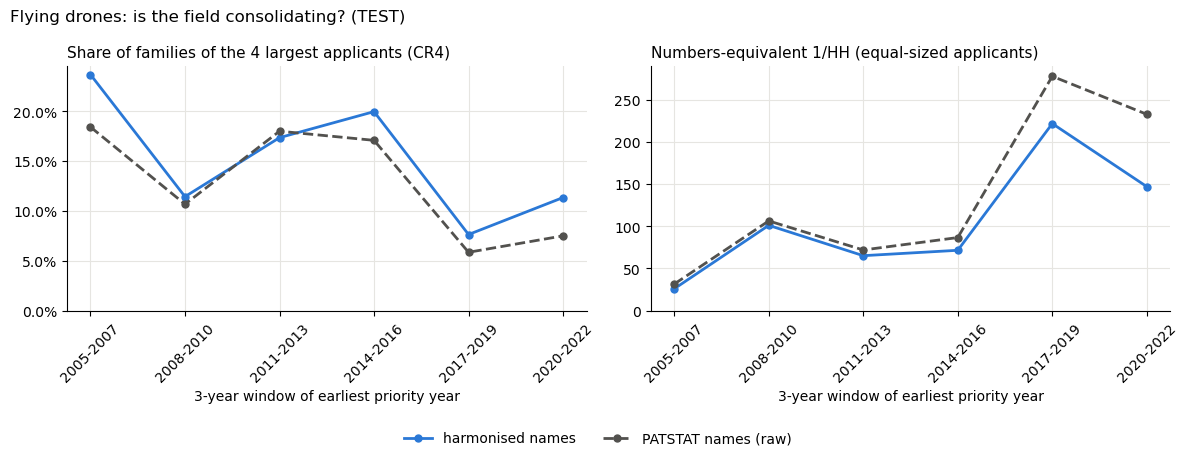

In [10]:
from matplotlib.ticker import PercentFormatter

C_MAIN, C_MUTED, C_GRID = "#2a78d6", "#52514e", "#e6e5e1"   # blue for harmonised, grey for raw
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": C_GRID, "axes.axisbelow": True, "legend.frameon": False})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
panels = [(axes[0], "CR4_pct", "Share of families of the 4 largest applicants (CR4)"),
          (axes[1], "numbers_equivalent_1_over_HH", "Numbers-equivalent 1/HH (equal-sized applicants)")]
series = [("harmonised", "harmonised names", C_MAIN, "-"), ("raw", "PATSTAT names (raw)", C_MUTED, "--")]

for ax, col, title in panels:
    for names, label, color, style in series:
        t = trend[trend["names"] == names].sort_values("start")
        ax.plot(t["window"], t[col], linestyle=style, color=color, marker="o", markersize=5, lw=2, label=label)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(f"{WINDOW}-year window of earliest priority year")
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(bottom=0)
axes[0].yaxis.set_major_formatter(PercentFormatter(100))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"{SECTOR_NAME}: is the field consolidating? ({ENV})", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(OUT / "fig_step2_concentration_trend.png", dpi=200, bbox_inches="tight")

plt.show()

In [11]:
#non mandatory, we can delete but it creates the answer 

MIN_FAMILIES_WINDOW = 50   # windows with fewer families are too small to compare

h = (trend[(trend["names"] == "harmonised") & (trend["families"] >= MIN_FAMILIES_WINDOW)]
     .sort_values("start").set_index("window"))
whole = conc["Harmonised (Team 28)"]
first, last = h.iloc[0], h.iloc[-1]
peak = h["CR4_pct"].idxmax()

signals = sum([last["HH"] > first["HH"],
               last["CR4_pct"] > first["CR4_pct"],
               last["numbers_equivalent_1_over_HH"] < first["numbers_equivalent_1_over_HH"]])
verdict = {3: "more concentrated (consolidating)", 0: "less concentrated (more and more players)"}.get(signals, "mixed signals")

print("Q: How concentrated is the field, and is it consolidating?")
print(f"A: Over {YEAR_MIN}-{LAST_COMPLETE_YEAR} the 4 largest applicants hold {whole['CR4_pct']:.1f}% of the families "
      f"(HH = {whole['HH']:.4f}, like {whole['numbers_equivalent_1_over_HH']:.0f} equal-sized applicants): a fragmented field.")
print(f"   From {h.index[0]} to {h.index[-1]}: CR4 {first['CR4_pct']:.1f}% -> {last['CR4_pct']:.1f}%, "
      f"1/HH {first['numbers_equivalent_1_over_HH']:.0f} -> {last['numbers_equivalent_1_over_HH']:.0f}, "
      f"applicants {first['n_applicants']:.0f} -> {last['n_applicants']:.0f}: {verdict}.")
print(f"   CR4 peaked in {peak} ({h.loc[peak, 'CR4_pct']:.1f}%). "
      f"Windows with fewer than {MIN_FAMILIES_WINDOW} families are left out of the comparison.")

Q: How concentrated is the field, and is it consolidating?
A: Over 2004-2022 the 4 largest applicants hold 9.7% of the families (HH = 0.0041, like 243 equal-sized applicants): a fragmented field.
   From 2008-2010 to 2020-2022: CR4 11.4% -> 11.3%, 1/HH 101 -> 147, applicants 148 -> 302: less concentrated (more and more players).
   CR4 peaked in 2014-2016 (20.0%). Windows with fewer than 50 families are left out of the comparison.
